# 01 : Data exploration and cleaning (Step 2)

In [1]:
import json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 4)

SEED = 42
np.random.seed(SEED)

# paths relative to the notebooks/ folder
ROOT = Path("..")
RESULTS = ROOT / "results"
FIGURES = ROOT / "report" / "figures"
RESULTS.mkdir(exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

CATEGORICAL = ["job", "marital", "education", "default", "housing", "loan",
               "contact", "month", "day_of_week", "poutcome"]
NUMERIC = ["age", "campaign_log", "pdays_clean", "prev_contacted", "previous",
           "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
from scipy import stats

In [2]:
raw = pd.read_csv(ROOT / "dataset" / "raw" / "bank-additional-full.csv", sep=";")
raw["row_order"] = np.arange(len(raw))   # the rows are in time order; we keep the position for later
print(raw.shape)
raw.head()

(41188, 22)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,row_order
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,1
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,3
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,4


## 1. Data quality
There are no empty cells, but some missing values are written as `"unknown"`, and `pdays = 999` means
"never contacted before".

In [3]:
cols = raw.columns.drop("row_order")
quality = pd.DataFrame({
    "dtype": raw[cols].dtypes.astype(str),
    "n_unique": raw[cols].nunique(),
    "n_nan": raw[cols].isna().sum(),
    "n_unknown": (raw[cols].astype(str) == "unknown").sum(),
})
quality["pct_unknown"] = (100 * quality.n_unknown / len(raw)).round(2)
quality.to_csv(RESULTS / "quality_report.csv")
quality

,dtype,n_unique,n_nan,n_unknown,pct_unknown
age,int64,78,0,0,0.00
job,str,12,0,330,0.80
marital,str,4,0,80,0.19
education,str,8,0,1731,4.20
default,str,3,0,8597,20.87
housing,str,3,0,990,2.40
loan,str,3,0,990,2.40
contact,str,2,0,0,0.00
month,str,10,0,0,0.00
day_of_week,str,5,0,0,0.00


In [4]:
print("duplicate rows:", raw[cols].duplicated().sum())
print("share of pdays == 999:", round((raw.pdays == 999).mean(), 4))
print("rows with default == 'yes':", (raw.default == "yes").sum())

duplicate rows: 12
share of pdays == 999: 0.9632
rows with default == 'yes': 3


## 2. The target is unbalanced

y
no     36548
yes     4640
Name: count, dtype: int64 
share of yes: 0.1127


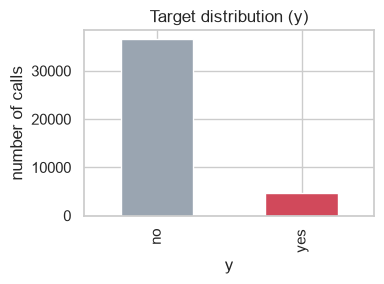

In [5]:
vc = raw.y.value_counts(); print(vc, "\nshare of yes:", round((raw.y == "yes").mean(), 4))
fig, ax = plt.subplots(figsize=(4, 3)); vc.plot.bar(ax=ax, color=["#9aa5b1", "#d1495b"])
ax.set_title("Target distribution (y)"); ax.set_ylabel("number of calls"); plt.tight_layout()
plt.savefig(FIGURES / "target_balance.png", dpi=150); plt.show()

Only 11.3 % of the calls are a "yes". A model that always answers "no" already gets 88.7 % accuracy, so accuracy
is not a good metric here. We will mainly use the PR-AUC (area under the precision-recall curve).

## 3. Are the "unknown" values random?
We compare the subscription rate of the clients with `unknown` and of the others (chi-square test).
If the rates are different, "unknown" carries information and we should not delete or replace it.

In [6]:
rows = []
for c in ["job", "marital", "education", "default", "housing", "loan"]:
    unk = raw[c] == "unknown"
    chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(unk, raw.y))
    rows.append({"feature": c, "n_unknown": int(unk.sum()),
                 "rate_yes_if_unknown": (raw.y[unk] == "yes").mean(),
                 "rate_yes_if_known": (raw.y[~unk] == "yes").mean(), "p_value": p})
pd.DataFrame(rows)

,feature,n_unknown,rate_yes_if_unknown,rate_yes_if_known,p_value
0,job,330,0.1121,0.1127,1.0000e+00
1,marital,80,0.1500,0.1126,3.7857e-01
2,education,1731,0.1450,0.1112,1.6299e-05
3,default,8597,0.0515,0.1288,3.8513e-90
4,housing,990,0.1081,0.1128,6.8194e-01
5,loan,990,0.1081,0.1128,6.8194e-01


For `default`, 21 % of the values are unknown, and these clients subscribe much less (5.2 % against 12.9 %,
p < 0.001). So we keep `unknown` as a normal category.

## 4. Cleaning
We remove the 12 duplicates, turn `y` into 0/1, split `pdays` into "contacted before (yes/no)" and the number of days,
apply `log(1 + x)` to `campaign`, and remove `duration`. These steps work row by row, so they can be done before the
train/test split without leaking information.

In [7]:
df = raw.drop_duplicates(subset=cols).copy()
df["y"] = (df["y"] == "yes").astype(int)
df["prev_contacted"] = (df["pdays"] != 999).astype(int)        # 1 if contacted in a previous campaign
df["pdays_clean"] = np.where(df["pdays"] == 999, -1, df["pdays"])
df["campaign_log"] = np.log1p(df["campaign"])
df = df.drop(columns=["duration", "pdays", "campaign"]).reset_index(drop=True)
print(df.shape); df.head()

(41176, 22)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,row_order,prev_contacted,pdays_clean,campaign_log
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1.1,93.994,-36.4,4.857,5191.0,0,0,0,-1,0.6931
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1.1,93.994,-36.4,4.857,5191.0,0,1,0,-1,0.6931
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1.1,93.994,-36.4,4.857,5191.0,0,2,0,-1,0.6931
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1.1,93.994,-36.4,4.857,5191.0,0,3,0,-1,0.6931
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1.1,93.994,-36.4,4.857,5191.0,0,4,0,-1,0.6931


### Why we remove `duration`
`duration` is the length of the call. We only know it after the call, when we already know the answer
(a call of 0 seconds is always a "no"). Using it would be cheating, as the dataset description also says.

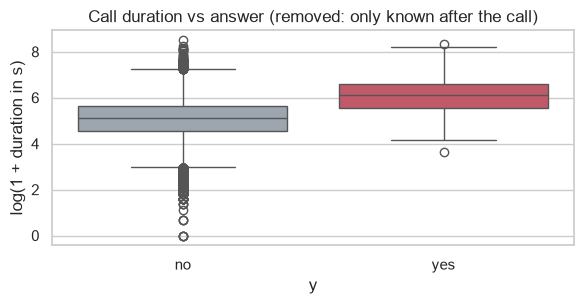

calls with duration 0 and answer yes: 0


In [8]:
fig, ax = plt.subplots(figsize=(6, 3.2))
sns.boxplot(x=raw.y, y=np.log1p(raw.duration), ax=ax, palette=["#9aa5b1", "#d1495b"])
ax.set_ylabel("log(1 + duration in s)"); ax.set_title("Call duration vs answer (removed: only known after the call)")
plt.tight_layout(); plt.savefig(FIGURES / "duration_leak.png", dpi=150); plt.show()
print("calls with duration 0 and answer yes:", ((raw.duration == 0) & (raw.y == "yes")).sum())

## 5. Distributions and outliers

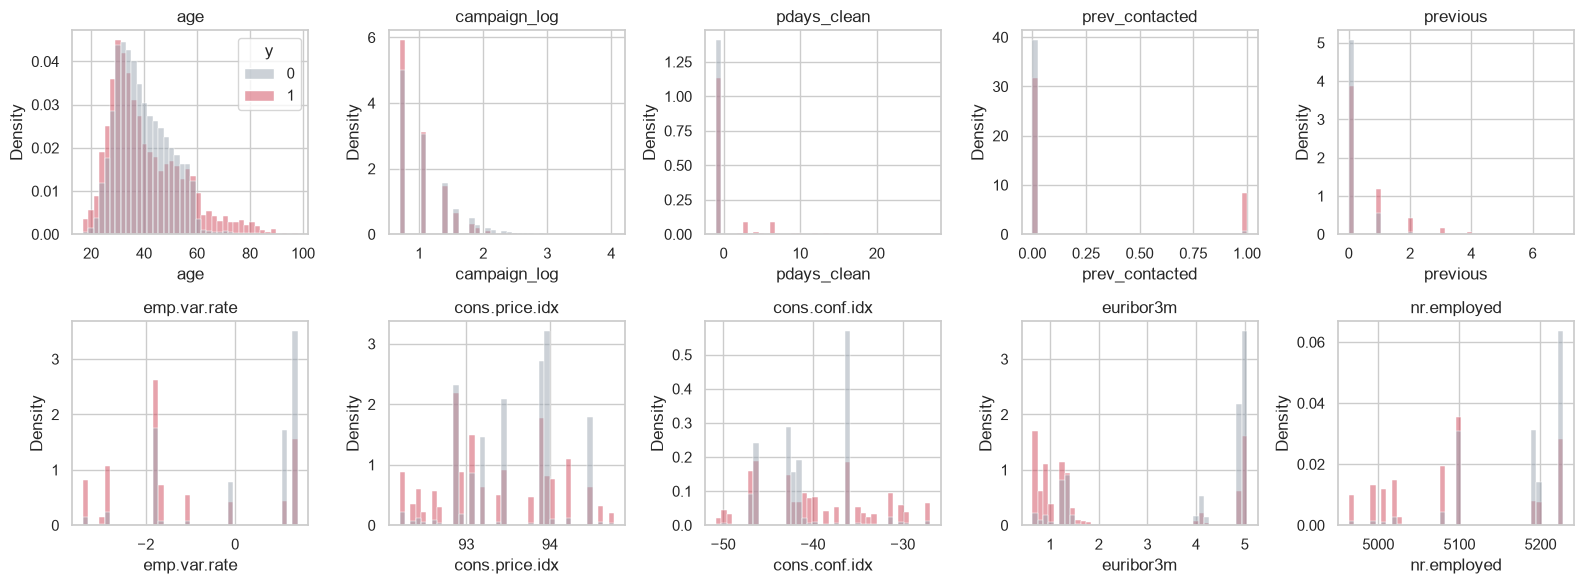

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, c in zip(axes.ravel(), NUMERIC):
    sns.histplot(data=df, x=c, hue="y", stat="density", common_norm=False, bins=40, ax=ax,
                 palette=["#9aa5b1", "#d1495b"], legend=(c == NUMERIC[0]))
    ax.set_title(c)
plt.tight_layout(); plt.savefig(FIGURES / "numeric_distributions.png", dpi=130); plt.show()

In [10]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return int(((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum())
pd.DataFrame({"campaign (raw)": [iqr_outliers(raw.campaign)], "campaign (log)": [iqr_outliers(df.campaign_log)],
              "age": [iqr_outliers(df.age)], "previous": [iqr_outliers(df.previous)]}, index=["IQR outliers"])

,campaign (raw),campaign (log),age,previous
IQR outliers,2406,869,468,5625


The extreme values look real (a client called 56 times, a client aged 98), not like errors, so we keep them.
The log transformation reduces the skew of `campaign`, and tree models are not sensitive to extreme values anyway.

## 6. Which variables are linked to the target?
* **Categorical variables:** chi-square test + Cramér's V (strength of the link, between 0 and 1).
  The chi-square test needs at least 5 expected observations in each cell, so we check it.
* **Numerical variables:** the distributions are not normal (`normaltest_p` ≈ 0), so we use the Mann-Whitney test
  instead of a t-test, with the rank-biserial correlation as strength of the link.
* With 41,000 rows almost every p-value is tiny, so we compare variables using the strength of the link.

In [11]:
def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    return float(np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1))))

def chi2_tests(df, min_count=0):
    rows = []
    for c in CATEGORICAL:
        col, target, n_excluded = df[c], df["y"], 0
        if min_count:
            # group the categories with fewer than min_count rows into 'other'
            counts = col.value_counts()
            col = col.where(~col.isin(counts[counts < min_count].index), "other")
            # if 'other' is still too small, leave these rows out of the test (see AI_AUDIT.md, Baudouin Parent)
            ct0 = pd.crosstab(col, target)
            expected0 = stats.chi2_contingency(ct0)[3]
            too_small = ct0.index[(expected0 < 5).any(axis=1)]
            n_excluded = int(col.isin(too_small).sum())
            keep = ~col.isin(too_small)
            col, target = col[keep], target[keep]
        chi2, p, dof, expected = stats.chi2_contingency(pd.crosstab(col, target))
        rows.append({"feature": c, "chi2": chi2, "dof": dof, "p_value": p, "min_expected": expected.min(),
                     "n_excluded": n_excluded, "cramers_v": cramers_v(col, target)})
    return pd.DataFrame(rows).sort_values("cramers_v", ascending=False)

cat_raw = chi2_tests(df)
cat_raw[cat_raw.min_expected < 5]

,feature,chi2,dof,p_value,min_expected,n_excluded,cramers_v
3,default,406.5561,2,5.2175e-89,0.3380,0,0.0994
2,education,192.8485,7,3.7468e-38,2.0279,0,0.0684


The condition of the chi-square test is not met for `default` (only 3 rows with `yes`) and `education`
(18 rows with `illiterate`). We group the categories with fewer than 20 rows into `other`; when this group is still
too small, we leave these rows out of the test (`n_excluded`).

In [12]:
cat_t = chi2_tests(df, min_count=20)
assert (cat_t.min_expected >= 5).all()   # the condition of the test is now checked
cat_t

,feature,chi2,dof,p_value,min_expected,n_excluded,cramers_v
9,poutcome,4230.1434,2,0.0000e+00,154.6859,0,0.3205
7,month,3103.0327,9,0.0000e+00,20.5046,0,0.2745
0,job,961.7438,11,3.2684e-199,37.1787,0,0.1528
6,contact,862.0807,1,1.7187e-189,1694.5599,0,0.1448
3,default,405.3768,1,3.7195e-90,968.5193,3,0.0993
2,education,190.7571,6,1.7563e-38,194.8236,18,0.0681
1,marital,122.9593,3,1.7784e-26,9.0130,0,0.0546
8,day_of_week,26.0542,4,3.0858e-05,881.6984,0,0.0252
4,housing,5.7422,2,5.6638e-02,111.5361,0,0.0118
5,loan,1.0993,2,5.7715e-01,111.5361,0,0.0052


`housing` and `loan` are not linked to the target (p > 0.05). We keep them, but they should not matter much.

In [13]:
rows = []
for c in NUMERIC:
    yes, no = df.loc[df.y == 1, c], df.loc[df.y == 0, c]
    u, p = stats.mannwhitneyu(yes, no, alternative="two-sided")
    rows.append({"feature": c, "skew": stats.skew(df[c]), "normaltest_p": stats.normaltest(df[c])[1],
                 "MWU_p": p, "rank_biserial": 2 * u / (len(yes) * len(no)) - 1})
num_t = pd.DataFrame(rows).sort_values("rank_biserial", key=abs, ascending=False)
num_t

,feature,skew,normaltest_p,MWU_p,rank_biserial
9,nr.employed,-1.0443,0.0000e+00,0.0000e+00,-0.4979
8,euribor3m,-0.7092,0.0000e+00,0.0000e+00,-0.4868
5,emp.var.rate,-0.7240,0.0000e+00,0.0000e+00,-0.4334
6,cons.price.idx,-0.2308,0.0000e+00,1.4428e-135,-0.2210
4,previous,3.8313,0.0000e+00,0.0000e+00,0.2186
3,prev_contacted,4.9211,0.0000e+00,0.0000e+00,0.1935
2,pdays_clean,7.3210,0.0000e+00,0.0000e+00,0.1934
1,campaign_log,1.3502,0.0000e+00,3.6294e-38,-0.1104
7,cons.conf.idx,0.3029,5.1470e-204,7.1013e-17,0.0744
0,age,0.7845,0.0000e+00,1.5638e-02,-0.0217


In [14]:
cat_t.to_csv(RESULTS / "chi2_tests.csv", index=False); num_t.to_csv(RESULTS / "mwu_tests.csv", index=False)

## 7. Correlations between variables

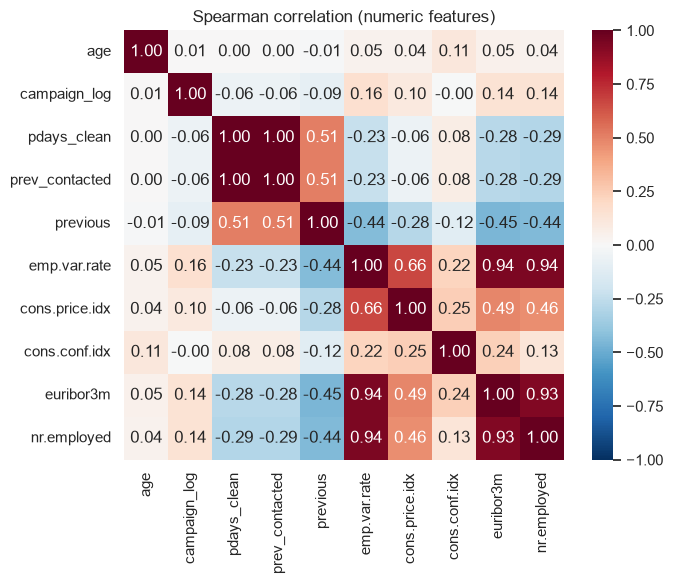

In [15]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(df[NUMERIC].corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation (numeric features)"); plt.tight_layout()
plt.savefig(FIGURES / "correlation.png", dpi=150); plt.show()

In [16]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
Xv = add_constant(df[NUMERIC].astype(float))
vif = pd.DataFrame({"feature": NUMERIC,
                    "VIF": [variance_inflation_factor(Xv.values, i + 1) for i in range(len(NUMERIC))]})
vif = vif.sort_values("VIF", ascending=False); vif.to_csv(RESULTS / "vif.csv", index=False); vif

,feature,VIF
8,euribor3m,64.5146
5,emp.var.rate,33.2825
9,nr.employed,31.7105
6,cons.price.idx,6.3313
3,prev_contacted,4.8982
2,pdays_clean,4.2866
7,cons.conf.idx,2.6502
4,previous,1.7975
1,campaign_log,1.0389
0,age,1.0190


`emp.var.rate`, `euribor3m` and `nr.employed` are almost the same information (correlation above 0.9, VIF above 30):
they all describe the economic situation. We keep them: trees are not affected, and the logistic regression is
regularised. We just avoid interpreting its coefficients one by one.

## 8. The data changes over time
The rows are in chronological order. We look at the share of "yes" in each tenth of the data.

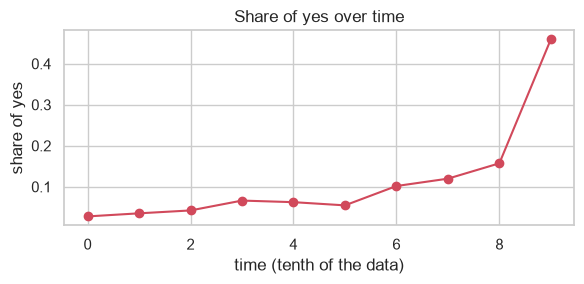

[0.028, 0.035, 0.042, 0.066, 0.062, 0.055, 0.102, 0.12, 0.157, 0.459]

In [17]:
dec = df.groupby(pd.qcut(df.row_order, 10, labels=False))["y"].mean()
fig, ax = plt.subplots(figsize=(6, 3)); dec.plot(marker="o", ax=ax, color="#d1495b")
ax.set_xlabel("time (tenth of the data)"); ax.set_ylabel("share of yes"); ax.set_title("Share of yes over time")
plt.tight_layout(); plt.savefig(FIGURES / "temporal_drift.png", dpi=150); plt.show(); dec.round(3).tolist()

The share of "yes" goes from 3 % at the beginning to 46 % at the end (after the 2008 crisis, the bank made fewer
but better-targeted calls). Our main split is random, but in notebook 04 we also test the models on the most
recent calls to see how they cope with this change.

## Summary of the preprocessing choices
| Problem | What we saw | What we do |
|---|---|---|
| `duration` | only known after the call | removed |
| `unknown` values | different rate of yes | kept as a category |
| `pdays = 999` | 96 % of rows | yes/no column + number of days |
| skewed `campaign` | skewness 4.8 | log(1 + x) |
| rare categories | e.g. 3 rows with `default=yes` | grouped by the encoder (fewer than 20 rows) |
| 12 duplicates | identical rows | removed before the split |
| correlated economic variables | VIF above 30 | kept, regularised logistic regression |
| 11 % of yes | — | PR-AUC as main metric |

Scaling and one-hot encoding are not done here: they are part of the model pipeline, so they are only fitted
on the training data.

## 9. Saving the clean dataset
The next notebooks start from this file.

In [18]:
(ROOT / "dataset" / "processed").mkdir(parents=True, exist_ok=True)
df.to_csv(ROOT / "dataset" / "processed" / "bank_clean.csv", index=False)
print(df.shape, "saved")

(41176, 22) saved
